# **Assignment 4: Feature Engineering**

## EDA of Refah Iranian Dataset

## Author: Mohammad Mehdi Zare, Mohammad Ali Olama

# Abstract

This report continues on the **Refah Iranian** dataset. The primary objective of this project is to perform feature engineering in the dataset. For simplicity, we are using the cleaned dataset accquired from HW2.

# Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install arabic_reshaper

In [ ]:
!pip install python-bidi

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
from matplotlib.category import UnitData

# We need these libraries for Farsi writting
import arabic_reshaper
import bidi.algorithm

wr.filterwarnings('ignore')

# Display all columns in DataFrame format
pd.set_option('display.max_columns', None)

# **Read dataset**

This part is a repeatition of a part of the previous assingment. We load the dataset and perform some cleaning.

In [ ]:
df_org=pd.read_csv("/content/drive/MyDrive/TEIAS/ADS/HW4/nemone_2_darsadi_1402_cleaned.csv")

In [ ]:
df = df_org
df.head()

# Feature Enginnering


## Combining columns
We decided to aggregate total sum of trips for each person. So we aggregate air trips and non-air trips for each person:

In [ ]:
df['TripCountAir'] = df['TripCountAirPilgrimage_95to99'] + df['TripCountAirNonPilgrimage_95to99'];
df['TripCountNonAir'] = df['TripCountNonAirPilgrimage_95to99'] + df['TripCountNonAirNonPilgrimage_95to99'];

we can do the same for categorical features too. Since our dataset has integer binary gategorizes, we can't simply do this. So we transform two columns and then combine them!

In [ ]:
def combine_columns(row):
  if row['ISBimarKhas'] == 1 and row['IsMalool'] == 1:
    return 'Malool-Bimar'
  elif row['ISBimarKhas'] == 1 and row['IsMalool'] == 0:
    return 'Salem-Bimar'
  elif row['ISBimarKhas'] == 0 and row['IsMalool'] == 1:
    return 'Malool-Salem'
  else:
    return 'Salem-Salem'   # Or any other default value you prefer

df['HealthIndicator'] = df.apply(combine_columns, axis=1)

In [ ]:
df.head()

we create another column to see from how many governmental sources does each person receive aid.

In [ ]:
def combine_columns(df):
  return df['IsBehzisti_AfzayeshMostamari'] + df['IsKomite_AfzayeshMostamari'] + df['IsKomite_AfzayeshMostamariSayer']

df['GovernmentAssistantLevel'] = df.apply(combine_columns, axis=1)

In [ ]:
df['GovernmentAssistantLevel'].value_counts()

,count
GovernmentAssistantLevel,
0.0,1565006
1.0,128568
2.0,4208
3.0,34


# جمع فیچر های عددی
ما تصمیم گرفتیم که تمام تراکنش های مالی اشخاص را با یکدیگر جمع کنیم. از آنجا که تمام این ستون ها، واحد یکسانی دارند، بنابراین نیازی به تبدیل واحد نداریم. اما برای اینکه با تورم مواجه هستیم، ارزش پول در سال های مختلف با یکدیگر متفاوت است. در نتیجه یک نرخ تنزیل 44 درصد در نظر گرفتیم و با استفاده از آن تمام مقادیر عددی که مربوط به انتقال وجه افزاد هست را با یکدیگر جمع میکنیم.
(توضیح به انگلیسی سخت بود =) )

In [ ]:
'''
جمع سانتا و پایا
نرخ تنزیل 44 درصد
'SatnaPerMonth_1401'
'SatnaPerMonth_1402'
'PayaPerMonth_1401'
'PayaPerMonth_1402'
'''
i=0.44
paya_satna_1402=(df['SatnaPerMonth_1401']*(1+i))+(df['SatnaPerMonth_1402'])+(df['PayaPerMonth_1401']*(1+i))+(df['PayaPerMonth_1402'])

'''
جمع کارت به کارت
نرخ تنزیل 44 درصد
'CardBeCardPerMonth_1401'
'CardBeCardPerMonth_1402'
'''
i=0.44
CBC_1402=(df['CardBeCardPerMonth_1401']*(1+i))+(df['CardBeCardPerMonth_1402'])



'''
.ارزش زمانی کلیه معاملات پولی را با استفاده از نرخ تنزیل 44 درصد با استفاده از فرمول زیر برای 1402 محاسبه میکنیم
FV=PV(1+i)**n

'CardPerMonth_1398'
'CardPerMonth_1399'
'CardPerMonth_1400'
'CardPerMonth_1401'
'CardPerMonth_1402'
'''
i=0.44
n_98=1402-1398
n_99=1402-1399
n_400=1402-1400
n_401=1402-1401
card_p_m_by_1402=(df['CardPerMonth_1398']*(1+i)**n_98)+(df['CardPerMonth_1399']*(1+i)**n_99) +(df['CardPerMonth_1400']*(1+i)**n_400)+(df['CardPerMonth_1401']*(1+i)**n_401)+df['CardPerMonth_1402']




df['gardesh_mali']=paya_satna_1402 + CBC_1402 + card_p_m_by_1402
df['gardesh_mali']


,gardesh_mali
0,1.496880e+04
1,5.836111e+08
2,2.524486e+10
3,1.273122e+08
4,1.680295e+09
...,...
1697811,1.496736e+04
1697812,1.098811e+08
1697813,5.620796e+08
1697814,3.993756e+07


In [ ]:
'''
باهدف نتیجه گبری  دقیق تر  وضعبت مالی  دادهای ماهانه چندسال را در نظر مگیریم و با استفاده از مفهوم ارزش زمانی پول با نرخ تنزیل 44 درصد برای 1402 محاسبه میکنیم.
محاسبه میانگین مانده اول و آخر سالهای موجود
'MandehAval_1399'
'MandehAkhar_1399'
'MandehAval_1400'
'MandehAkhar_1400'
'''


# محاسبه معدل حساب برای سالهای 99 و 1400 بصورت میانگین مانده اول و آخر سال
mean_99=df[['MandehAval_1399','MandehAkhar_1399']].aggregate('mean' , axis=1)
mean_400=df[['MandehAval_1400','MandehAkhar_1400']].aggregate('mean' , axis=1)


# تنزیل مانده های سال های 99 و 400 با نرخ 44 درصد با هدف اینکه مانده های پولی قابل مقایسه باشد
# با استفاده از فرمول زیر
# FV=PV(1+i)**n
n_99=1402-1399
n_400=1402-1400
i=0.44
df['mandeh_1402']=(mean_99*(1+i)**n_99)+(mean_400*(1+i)**n_400)



حالا، ما یک ستون جدید برحسب "گردش مالی" و "مانده حساب" ایجاد میکنیم. این ستون نشان دهنده تراکنش های انجام شده اشخاص خواهد بود.

In [ ]:
df['Transactions']=df['gardesh_mali']+df['mandeh_1402']


حالا یک دیتاست جدید برحسب دیتاست فعلی میسازیم. در این دیتاست جدید، افراد یک خانوار را برحسب
parent_id
آنها شناسایی میکنیم و همه را در یک گروه قرار میدهیم.


In [ ]:
grouped_df = df.groupby('Parent_Id').agg({
    'Transactions': 'sum',        # Sum the 'servat' values for each 'parent_id'
    'Decile': 'first',      # Keep the first 'Decile' value (assumed to be the same for each 'parent_id')
    'Age': 'mean',
    'id': 'count',
    'TripCountAir': 'sum',
    'TripCountNonAir': 'sum',
    'Has_Saham_Edalat': 'first',
    'CarsCount': 'sum',
    'CarsPrice': 'sum',
    'ISBimarKhas': 'sum',
    'IsMalool': 'sum',
    'Daramad': 'sum'
}).reset_index()
grouped_df = grouped_df.rename(columns={'id': 'memberCount' , 'ISBimarKhas' : 'BimarKhasCount' , 'IsMalool' : 'MaloolCount'})



سپس جنسیت سرپرست خانوار و همچنین سطح تسهیلات دریافتی از دولت(بهزیستی و کمیته امداد) را به این دیتاست اضافه میکنیم.

In [ ]:
grouped_df2 = df[df['Parent_Id'] == df['id']][['Parent_Id' , 'GenderId' , 'GovernmentAssistantLevel']]
grouped_df = grouped_df.merge(grouped_df2, on='Parent_Id' , how='left')

In [ ]:
grouped_df

# Ratio

مجموع تراکنش های یک خانوار را به تعداد اعضای خانوار تقسیم میکنیم و ستون جدیدی بدست می آوریم.

In [ ]:
grouped_df['household_net_worth'] = grouped_df['Transactions'] / grouped_df['memberCount']

In [ ]:
grouped_df.head()

## Binning
ما میانگین سن افراد هر خانوار را حساب کرده ایم. در اینجا برحسب اینکه این میانگین چقدر است، خانوار ها را به گروه های سنی مختلف تقسیم میکنیم.

In [ ]:
bins = [0, 30, 55, 100]

labels = ['Young','Middle-Age','Old']
grouped_df['age_cat'] = pd.cut(grouped_df['Age'], bins=bins, labels=labels)

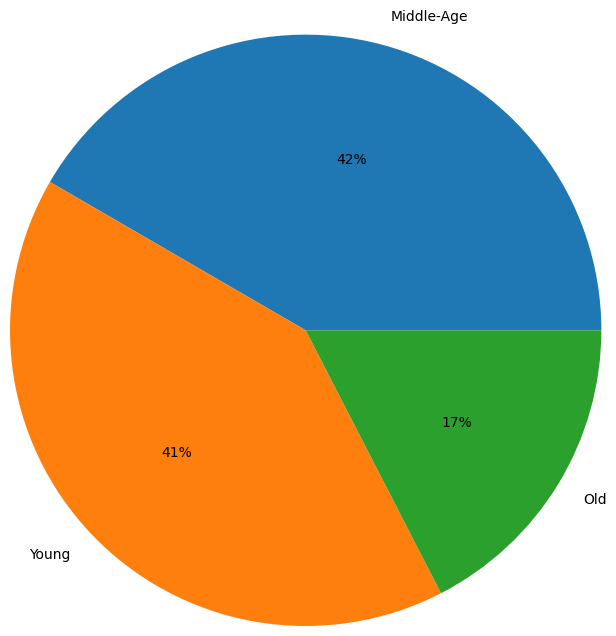

In [ ]:
grouped_df['age_cat'].value_counts().plot.pie(autopct='%1.0f%%',radius=2,ylabel='')
plt.show()

# Mutal Information

Our target feature is 'Decile' and we wanted to predict decile of each household. So we estimate mutal information of other columns with respect to 'Decile'

In [ ]:
grouped_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 595688 entries, 0 to 595687
Data columns (total 17 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   Parent_Id                 595688 non-null  int64   
 1   Transactions              595688 non-null  float64 
 2   Decile                    595688 non-null  int64   
 3   Age                       595688 non-null  float64 
 4   memberCount               595688 non-null  int64   
 5   TripCountAir              595688 non-null  float64 
 6   TripCountNonAir           595688 non-null  float64 
 7   Has_Saham_Edalat          595688 non-null  float64 
 8   CarsCount                 595688 non-null  float64 
 9   CarsPrice                 595688 non-null  float64 
 10  BimarKhasCount            595688 non-null  float64 
 11  MaloolCount               595688 non-null  float64 
 12  Daramad                   595688 non-null  float64 
 13  GenderId                  595

In [ ]:
for colname in grouped_df.select_dtypes("category"):
    grouped_df[colname], _ = grouped_df[colname].factorize()

In [ ]:
# Now, pop the target values
target_column = grouped_df.pop('Decile')

In [ ]:
from sklearn.feature_selection import SelectKBest, mutual_info_regression
feature_selector = SelectKBest(score_func=mutual_info_regression, k = 'all').fit(grouped_df,target_column)

<Axes: ylabel='Feature'>

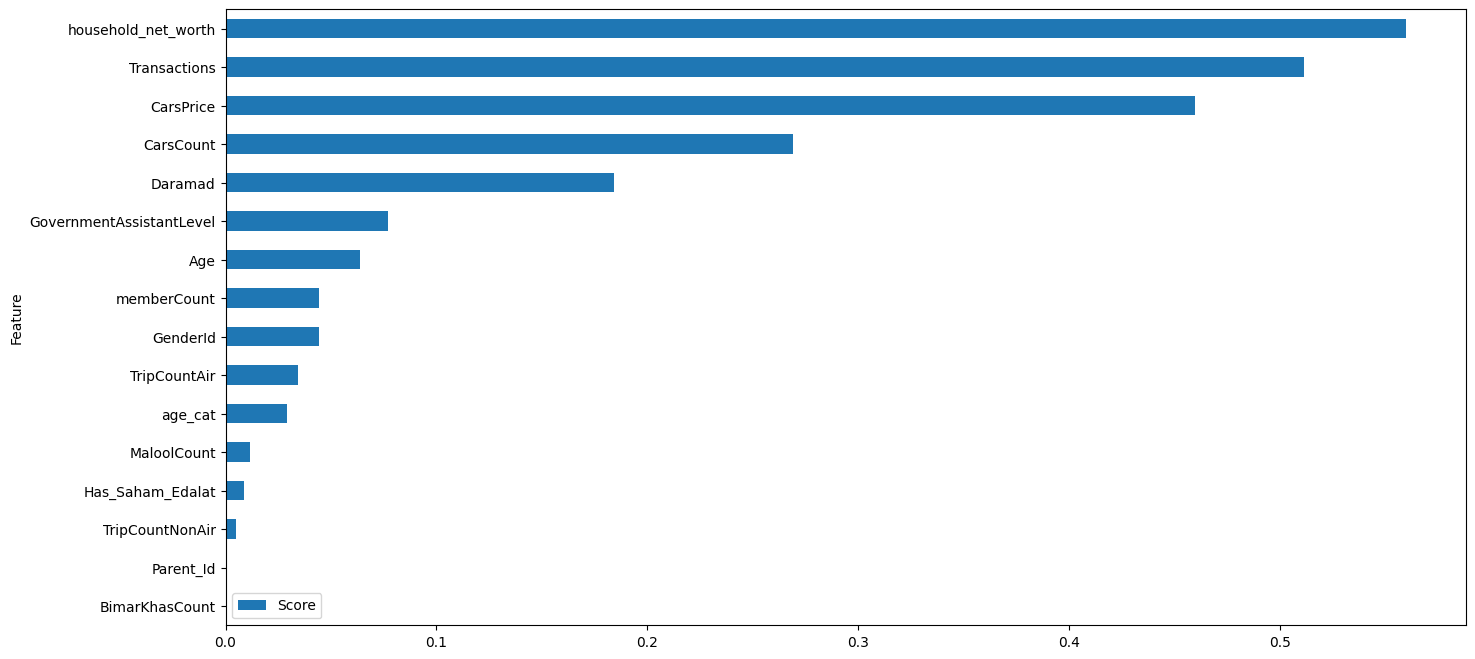

In [ ]:
feature_scores = pd.DataFrame({'Feature':grouped_df.columns,'Score':feature_selector.scores_})
feature_scores.sort_values(by=['Score'],inplace=True)

feature_scores[0:20].plot(x='Feature',y='Score',kind='barh',figsize=(16,8))

From the chart above, we can say that 'household_net_worth', which is a custom-made feature that we extracted from the data has the highest correlation with 'Decile'.

#PCA
in this last section, we perform PCA to reduce the dimenstion of our dataset.

In [ ]:
from sklearn.preprocessing import StandardScaler
normalized_df = StandardScaler().fit_transform(grouped_df)

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=16)
principalComponents = pca.fit_transform(normalized_df)
df_pca = pd.DataFrame(data = normalized_df)
df_pca.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,-1.732522,-0.182982,-0.393390,-0.603152,-0.139875,-0.090529,-1.119309,-0.821845,-0.318659,-0.147114,-0.204144,-0.765685,-0.535932,-0.324864,-0.103549,-1.039113
1,-1.732515,-0.254894,0.658500,0.815735,-0.139875,-0.090529,0.893408,0.152538,-0.240676,-0.147114,-0.204144,0.135663,-0.535932,-0.324864,-0.250776,-1.039113
2,-1.732514,-0.091795,-0.744020,-0.603152,-0.139875,-0.090529,0.893408,-0.821845,-0.318659,-0.147114,-0.204144,-0.196660,-0.535932,-0.324864,-0.010141,0.331738
3,-1.732507,-0.257592,0.278651,-0.603152,-0.139875,-0.090529,-1.119309,0.152538,-0.058775,-0.147114,-0.204144,0.890042,-0.535932,-0.324864,-0.179975,-1.039113
4,-1.732505,-0.141797,-1.030367,1.525178,-0.139875,-0.090529,-1.119309,-0.821845,-0.318659,-0.147114,-0.204144,0.253875,-0.535932,-0.324864,-0.219149,0.331738


Now that we have all the components, we can check how many components to keep, based on the amount of "details" the components provide us with about the data:

Text(0.5, 1.0, ' ')

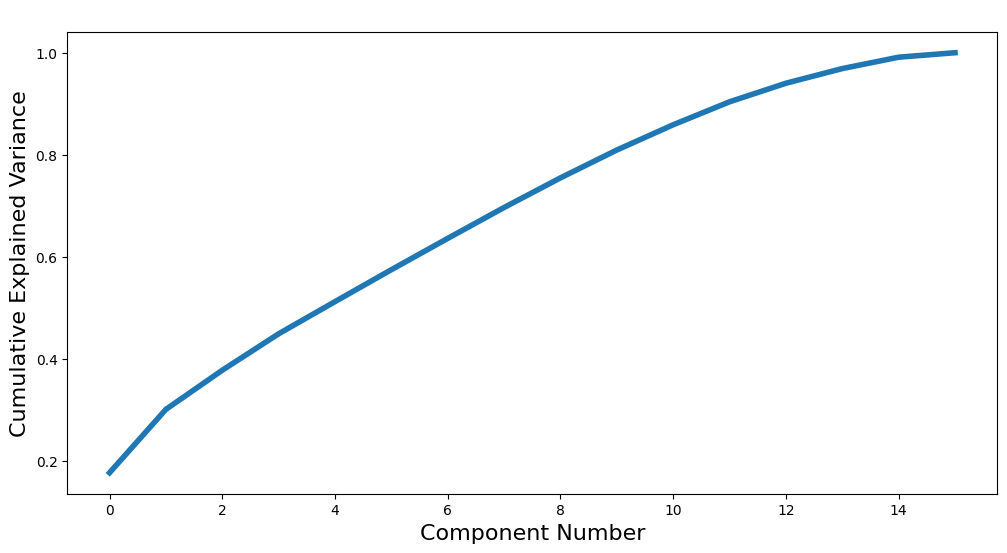

In [ ]:
from matplotlib.pyplot import figure

figure(figsize=(12, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_),lw=4)
plt.xlabel('Component Number',fontsize=16)
plt.ylabel('Cumulative Explained Variance',fontsize=16)
plt.title(' ')


# Final question: when is feature engineering a “nice to have option” and in what situations it is a “must to have”?

## "Nice to Have" Scenarios:

*   **Deep Learning with Large, Raw Data**: When we are using deep learning models (e.g., CNNs for image data) and had a large dataset, feature engineering might be less critical. Deep learning models can automatically learn complex patterns from raw data in layered manner, reducing the need for manual feature extraction. But if we manually enginner the features, we can help reduce time complexity for model.

* **Simple Problems or Models**: For tasks where patterns are straightforward or when simpler models like linear regression are sufficient, feature engineering might not drastically improve performance. Here, basic preprocessing steps (e.g., handling missing values, encoding categorical data) could be enough.

## "Must-Have" Scenarios:

* **Structured Data and Statistical ML**: Feature engineering is critical when working with structured/tabular data, especially with models like decision trees or gradient boosting. Crafting domain-specific features in finance or healthcare data can significantly improve accuracy and interpretability.

* **Small Datasets**: When your dataset is limited, feature engineering can compensate for the lack of data complexity or volume, enabling your model to capture meaningful patterns effectively. For example, this is the case when we are dealing with DNA strings, where the number of features (e.g. number of chars in the string) is much more than DNA smaples.

* **High Noise or Irrelevant Features**: If your data contains noisy or irrelevant features, crafting more robust and informative features through techniques like dimensionality reduction (e.g. PCA), aggregation, or encoding can significantly improve model performance and stability.